In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving startup_clean.csv to startup_clean.csv


In [ ]:
df = pd.read_csv('startup_clean.csv')

df.head()

,Unnamed: 0,Date,Startup,Industry,Location,Investor,Type,Amount
0,0,01-04-2021,BYJU'S,Education,Bangalore,Innoven Capital,Series F,460000000.0
1,1,05-04-2021,Meesho,E-Commerce,Bangalore,SoftBank Vision Fund 2,Series E,300000000.0
2,2,14-04-2021,Swiggy,Consumables,Bangalore,"Amansa Holdings, Carmignac, Falcon Edge Capita...",Series J,343000000.0
3,3,07-04-2021,Groww,Finance,Bangalore,"MC Global Edtech, B Capital, Baron, others",Series D,83000000.0
4,4,14-04-2021,Beldara,E-Commerce,Mumbai,Hindustan Media Ventures,Unknown,7400000.0


In [ ]:
df.shape


(550, 8)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  550 non-null    int64  
 1   Date        550 non-null    object 
 2   Startup     550 non-null    object 
 3   Industry    550 non-null    object 
 4   Location    550 non-null    object 
 5   Investor    550 non-null    object 
 6   Type        550 non-null    object 
 7   Amount      550 non-null    float64
dtypes: float64(1), int64(1), object(6)
memory usage: 34.5+ KB


In [ ]:
df.describe(include='all')

,Unnamed: 0,Date,Startup,Industry,Location,Investor,Type,Amount
count,550.000000,550,550,550,550,550,550,5.500000e+02
unique,NaN,218,292,19,19,302,15,NaN
top,NaN,08-08-2018,Shuttl,Software,Bangalore,Secret,Unknown,NaN
freq,NaN,12,6,214,218,26,212,NaN
mean,306.945455,NaN,NaN,NaN,NaN,NaN,NaN,4.602586e+07
std,178.991958,NaN,NaN,NaN,NaN,NaN,NaN,1.956201e+08
min,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,1.148110e+05
25%,155.250000,NaN,NaN,NaN,NaN,NaN,NaN,1.625000e+06
50%,308.000000,NaN,NaN,NaN,NaN,NaN,NaN,6.000000e+06
75%,460.750000,NaN,NaN,NaN,NaN,NaN,NaN,2.712500e+07


In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
Date,0
Startup,0
Industry,0
Location,0
Investor,0
Type,0
Amount,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
print("Unknown funding stages:")
print(df['Type'].value_counts())

print('\nUnkown investors:')
print(df['Investor'].value_counts().head(10))


Unknown funding stages:
Type
Unknown             212
Seed                168
Series A             43
Series B             32
Series C             28
Debt                 23
Series D             19
Series F              8
Series E              8
Equity and Debt       3
Series J              2
Secondary Market      1
Bridge                1
Series G              1
Series H              1
Name: count, dtype: int64

Unkown investors:
Investor
Secret                                                                                   26
InnoVen Capital                                                                           6
Sequoia Capital India                                                                     6
Alteria Capital                                                                           5
Falcon Edge                                                                               5
Saama Capital, SRI Capital, Beenext, and Pravega Ventures                                 4
Nexus

In [ ]:
print(df['Date'].head(10))
print("\nData type:",df['Date'].dtype)

0    01-04-2021
1    05-04-2021
2    14-04-2021
3    07-04-2021
4    14-04-2021
5    04-03-2021
6    31-03-2021
7    30-03-2021
8    30-03-2021
9    23-03-2021
Name: Date, dtype: object

Data type: object


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
converted_dates = pd.to_datetime(
    df['Date'],
    format = '%d-%m-%Y',
    errors = 'coerce'
)

df.loc[converted_dates.isna(),['Date','Startup']]

,Date,Startup
301,05/072018,Loan Tap
374,05/072018,Loan Tap
447,05/072018,Loan Tap
520,05/072018,Loan Tap


In [ ]:
df_clean = df.copy()

In [ ]:
df_clean.drop(columns=['Unnamed: 0'], inplace=True)

In [ ]:
df_clean['Date'] = pd.to_datetime(
    df_clean['Date'],
    format='%d-%m-%Y',
    errors='coerce'
)

In [ ]:
print(df_clean['Date'].dtype)

print("Invalid dates:",
      df_clean['Date'].isna().sum())

df_clean[df_clean['Date'].isna()]

datetime64[ns]
Invalid dates: 4


,Date,Startup,Industry,Location,Investor,Type,Amount
301,NaT,Loan Tap,Software,Mumbai,"Shunwei Capital, Tuscan Ventures, Ashish Goenk...",Unknown,6250000.0
374,NaT,Loan Tap,Software,Mumbai,"Shunwei Capital, Tuscan Ventures, Ashish Goenk...",Unknown,6250000.0
447,NaT,Loan Tap,Software,Mumbai,"Shunwei Capital, Tuscan Ventures, Ashish Goenk...",Unknown,6250000.0
520,NaT,Loan Tap,Software,Mumbai,"Shunwei Capital, Tuscan Ventures, Ashish Goenk...",Unknown,6250000.0


In [ ]:
print("Duplicate records:",df_clean.duplicated().sum())

Duplicate records: 219


In [ ]:
duplicates = df_clean[
    df_clean.duplicated(keep=False)
]

duplicates.sort_values(
    by=["Startup","Amount"]
).head(20)

,Date,Startup,Industry,Location,Investor,Type,Amount
309,2018-07-12,19th mile,Software,Gurgaon,"Rishi Vasudev, Excelsior Investments, Ritesh V...",Seed,180000.0
382,2018-07-12,19th mile,Software,Gurgaon,"Rishi Vasudev, Excelsior Investments, Ritesh V...",Seed,180000.0
455,2018-07-12,19th mile,Software,Gurgaon,"Rishi Vasudev, Excelsior Investments, Ritesh V...",Seed,180000.0
528,2018-07-12,19th mile,Software,Gurgaon,"Rishi Vasudev, Excelsior Investments, Ritesh V...",Seed,180000.0
267,2018-09-04,3HCare,Healthcare & Hospitality,Delhi,Secret,Seed,1000000.0
340,2018-09-04,3HCare,Healthcare & Hospitality,Delhi,Secret,Seed,1000000.0
413,2018-09-04,3HCare,Healthcare & Hospitality,Delhi,Secret,Seed,1000000.0
486,2018-09-04,3HCare,Healthcare & Hospitality,Delhi,Secret,Seed,1000000.0
310,2018-07-12,5th Vital,Healthcare & Hospitality,Bangalore,Brand Capital and Others,Seed,500000.0
383,2018-07-12,5th Vital,Healthcare & Hospitality,Bangalore,Brand Capital and Others,Seed,500000.0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df_clean = df_clean.drop_duplicates()

df_clean = df_clean.reset_index(drop = True)

In [ ]:
print("Original records:",len(df))
print("Cleaned records:", len(df_clean))

print("Remaining duplicates:",
      df_clean.duplicated().sum())

Original records: 550
Cleaned records: 331
Remaining duplicates: 0


In [ ]:
print("Invalid dates:",
      df_clean['Date'].isna().sum())

Invalid dates: 1


In [ ]:
df_clean['Amount'].describe()


,Amount
count,3.310000e+02
mean,5.815579e+07
std,2.434793e+08
min,1.148110e+05
25%,2.500000e+06
50%,8.000000e+06
75%,3.000000e+07
max,3.900000e+09


In [ ]:
df_clean.nlargest(10,'Amount')[
    ['Startup','Industry','Location','Date','Amount']
]

,Startup,Industry,Location,Date,Amount
182,Rapido Bike Taxi,Logistics,Bangalore,2019-08-27,3.900000e+09
76,Flipkart,E-Commerce,Bangalore,2020-07-15,1.200000e+09
155,Paytm,Finance,Noida,2019-11-25,1.000000e+09
298,True North,Finance,Mumbai,2018-08-30,6.000000e+08
157,Udaan,Logistics,Bangalore,2019-10-02,5.850000e+08
55,BYJU'S,Education,Bangalore,2020-09-08,5.000000e+08
0,BYJU'S,Education,Bangalore,2021-04-01,4.600000e+08
8,BYJU'S,Education,Bangalore,2021-03-30,4.600000e+08
165,GOQii,Healthcare & Hospitality,Outside India,2019-09-04,4.500000e+08
2,Swiggy,Consumables,Bangalore,2021-04-14,3.430000e+08


In [ ]:
df_clean.nsmallest(10,'Amount')[
    ['Startup','Industry','Location','Date','Amount']
]

,Startup,Industry,Location,Date,Amount
288,Enakshi,Software,Ahmedabad,2018-08-16,114811.0
277,ZiffyHomes,Software,Gurgaon,2018-08-03,120000.0
239,Nagpur Wholesale,E-Commerce,Nagpur,2018-12-04,143000.0
185,WizCounsel,Compliance,Delhi,2019-07-01,145000.0
311,MEngage,Healthcare & Hospitality,Jaipur,2018-07-13,175000.0
309,19th mile,Software,Gurgaon,2018-07-12,180000.0
320,kidovators,Education,Bangalore,2018-07-24,180000.0
84,FLYX,Gaming & Entertainment,Delhi,2020-07-14,200000.0
221,Azah,Healthcare & Hospitality,Gurgaon,2019-04-12,200000.0
252,Genius Corner,Education,Noida,2018-11-21,278000.0


In [ ]:
Q1 = df_clean['Amount'].quantile(0.25)
Q3 = df_clean['Amount'].quantile(0.75)
IQR = Q3 - Q1


lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean['Amount'] < lower_limit) |
    (df_clean['Amount'] > upper_limit)
]

print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)
print("Lower limit:",lower_limit)
print("Upper limit:",upper_limit)

print("Number of outliers:",len(outliers))

Q1: 2500000.0
Q3: 30000000.0
IQR: 27500000.0
Lower limit: -38750000.0
Upper limit: 71250000.0
Number of outliers: 50


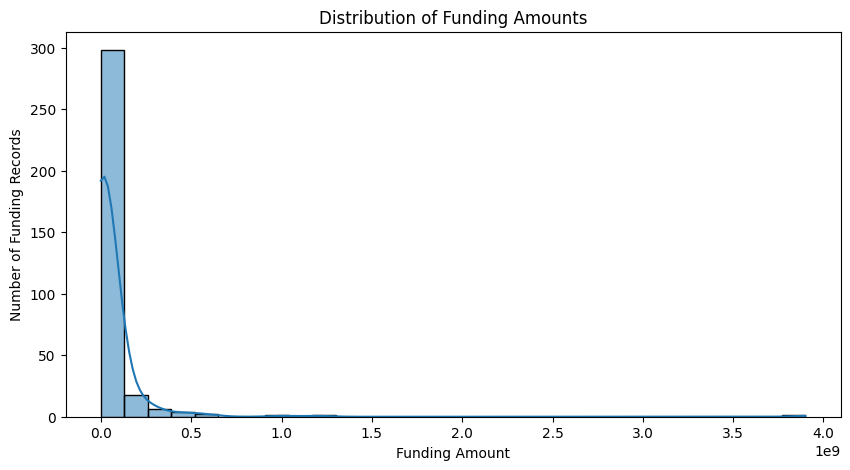

In [ ]:
plt.figure(figsize = (10,5))

sns.histplot(
    df_clean['Amount'],
    bins = 30 ,
    kde = True
)

plt.title('Distribution of Funding Amounts')
plt.xlabel('Funding Amount')
plt.ylabel('Number of Funding Records')
plt.show()

In [ ]:
outliers = df_clean[
    df_clean['Amount'] > upper_limit
]

outliers = outliers.sort_values(
    by='Amount',
    ascending = False
)

outliers[
    ['Startup','Industry','Location','Date','Amount']
].head(20)

,Startup,Industry,Location,Date,Amount
182,Rapido Bike Taxi,Logistics,Bangalore,2019-08-27,3.900000e+09
76,Flipkart,E-Commerce,Bangalore,2020-07-15,1.200000e+09
155,Paytm,Finance,Noida,2019-11-25,1.000000e+09
298,True North,Finance,Mumbai,2018-08-30,6.000000e+08
157,Udaan,Logistics,Bangalore,2019-10-02,5.850000e+08
55,BYJU'S,Education,Bangalore,2020-09-08,5.000000e+08
8,BYJU'S,Education,Bangalore,2021-03-30,4.600000e+08
0,BYJU'S,Education,Bangalore,2021-04-01,4.600000e+08
165,GOQii,Healthcare & Hospitality,Outside India,2019-09-04,4.500000e+08
2,Swiggy,Consumables,Bangalore,2021-04-14,3.430000e+08


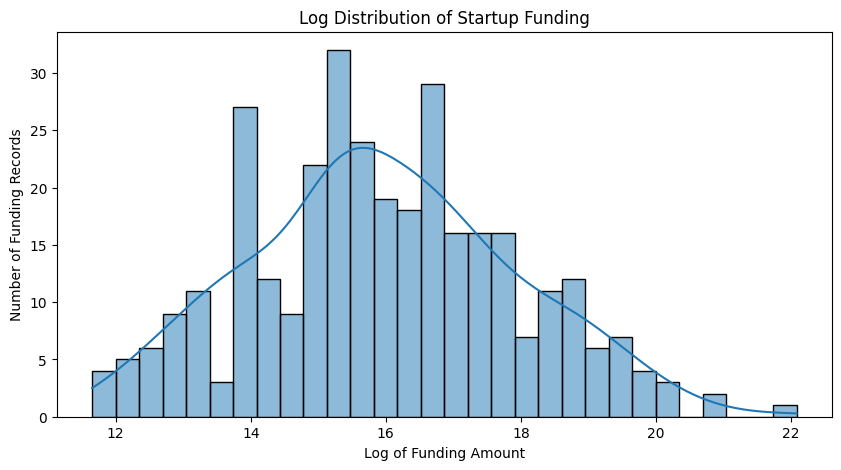

In [ ]:
plt.figure(figsize = (10,5))

sns.histplot(
    np.log1p(df_clean['Amount']),
    bins = 30,
    kde = True
)

plt.title('Log Distribution of Startup Funding')
plt.xlabel('Log of Funding Amount')
plt.ylabel('Number of Funding Records')
plt.show()

In [ ]:
print(df_clean['Location'].value_counts())

Location
Bangalore        128
Gurgaon           55
Mumbai            54
Delhi             25
Outside India     24
Pune               9
Hyderabad          8
Noida              7
Chennai            7
Jaipur             3
Patna              2
Ahmedabad          2
Faridabad          1
Amritsar           1
Haryana            1
Bhopal             1
Nagpur             1
Indore             1
Rourkela           1
Name: count, dtype: int64


In [ ]:
print(df_clean['Industry'].value_counts())

Industry
Software                     76
Finance                      54
E-Commerce                   48
Education                    32
Logistics                    25
Consumables                  22
Healthcare & Hospitality     22
Gaming & Entertainment       14
Cutting Edge Tech             9
Marketing                     6
Agriculture                   6
Lifestyle & Fashion           4
Automobile                    4
Energy & Waste Management     3
Real Estate                   2
Human Resources               1
Aerospace                     1
Retail                        1
Compliance                    1
Name: count, dtype: int64


In [ ]:
print(df_clean['Type'].value_counts())

Type
Seed                87
Unknown             86
Series A            43
Series B            32
Series C            25
Series D            19
Debt                17
Series F             8
Series E             5
Equity and Debt      3
Series J             2
Secondary Market     1
Bridge               1
Series G             1
Series H             1
Name: count, dtype: int64


In [ ]:
text_columns = [
    'Startup', 'Industry', 'Location',
    'Investor', 'Type'
]

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

In [ ]:
print(df_clean['Location'].value_counts())

Location
Bangalore        128
Gurgaon           55
Mumbai            54
Delhi             25
Outside India     24
Pune               9
Hyderabad          8
Noida              7
Chennai            7
Jaipur             3
Patna              2
Ahmedabad          2
Faridabad          1
Amritsar           1
Haryana            1
Bhopal             1
Nagpur             1
Indore             1
Rourkela           1
Name: count, dtype: int64


In [ ]:
print(df_clean['Industry'].value_counts())

Industry
Software                     76
Finance                      54
E-Commerce                   48
Education                    32
Logistics                    25
Consumables                  22
Healthcare & Hospitality     22
Gaming & Entertainment       14
Cutting Edge Tech             9
Marketing                     6
Agriculture                   6
Lifestyle & Fashion           4
Automobile                    4
Energy & Waste Management     3
Real Estate                   2
Human Resources               1
Aerospace                     1
Retail                        1
Compliance                    1
Name: count, dtype: int64


In [ ]:
print(df_clean['Type'].value_counts())

Type
Seed                87
Unknown             86
Series A            43
Series B            32
Series C            25
Series D            19
Debt                17
Series F             8
Series E             5
Equity and Debt      3
Series J             2
Secondary Market     1
Bridge               1
Series G             1
Series H             1
Name: count, dtype: int64


In [ ]:
industry_analysis = df_clean.groupby('Industry').agg(
    Total_Funding = ('Amount' , 'sum'),
    Average_Funding = ('Amount' , 'mean'),
    Meadian_Funding = ('Amount' , 'median'),
    Count = ('Amount' , 'count')
).reset_index()

industry_analysis = industry_analysis.sort_values(
    by = 'Total_Funding',
    ascending = False
)

industry_analysis

,Industry,Total_Funding,Average_Funding,Meadian_Funding,Count
14,Logistics,5.339074e+09,2.135630e+08,8048394.00,25
6,E-Commerce,3.786956e+09,7.889492e+07,15271000.00,48
9,Finance,2.837975e+09,5.255510e+07,9835000.00,54
7,Education,2.697427e+09,8.429458e+07,10780000.00,32
18,Software,1.882542e+09,2.477028e+07,6320000.00,76
11,Healthcare & Hospitality,1.086808e+09,4.940037e+07,5700000.00,22
4,Consumables,5.962759e+08,2.710345e+07,4300000.00,22
5,Cutting Edge Tech,3.829300e+08,4.254778e+07,5750000.00,9
1,Agriculture,1.949390e+08,3.248984e+07,8750000.00,6
15,Marketing,1.200000e+08,2.000000e+07,20000000.00,6


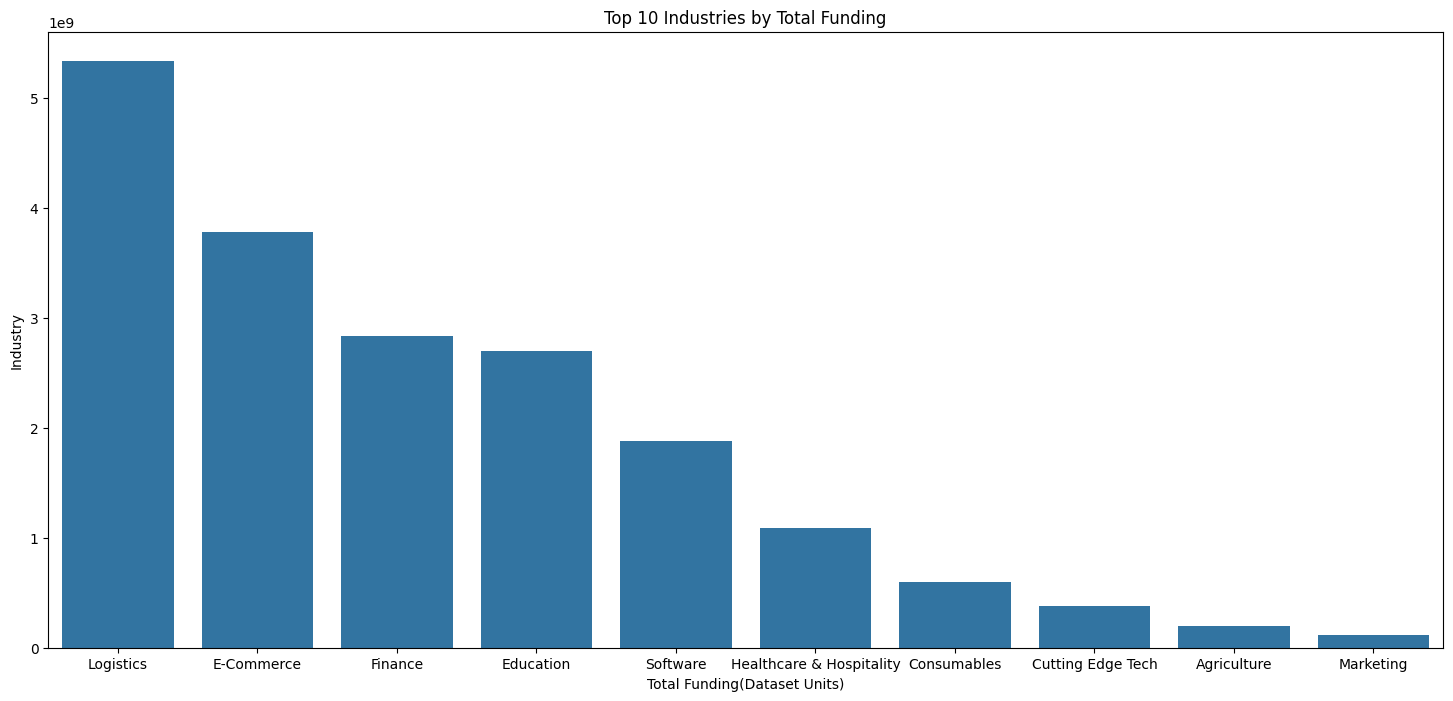

In [ ]:
top_industries = industry_analysis.head(10)

plt.figure(figsize=(18,8))

sns.barplot(
    data=top_industries,
    x='Industry',
    y='Total_Funding',
)

plt.title('Top 10 Industries by Total Funding')
plt.xlabel('Total Funding(Dataset Units)')
plt.ylabel('Industry')
plt.show()

In [ ]:
city_analysis = df_clean.groupby('Location').agg(
    Total_Funding = ('Amount' , 'sum'),
    Average_Funding = ('Amount' , 'mean'),
    Meadian_Funding = ('Amount' , 'median'),
    Funding_Records = ('Startup','count')
).reset_index()

city_analysis = city_analysis.sort_values(
    by = 'Total_Funding',
    ascending = False
)

city_analysis

,Location,Total_Funding,Average_Funding,Meadian_Funding,Funding_Records
2,Bangalore,1.119611e+10,8.746963e+07,8000000.0,128
15,Outside India,2.225219e+09,9.271746e+07,44540000.0,24
12,Mumbai,1.673975e+09,3.099953e+07,6125000.0,54
7,Gurgaon,1.279981e+09,2.327239e+07,10000000.0,55
14,Noida,1.113358e+09,1.590511e+08,15000000.0,7
17,Pune,4.581742e+08,5.090824e+07,4500000.0,9
5,Delhi,4.217823e+08,1.687129e+07,3591375.0,25
11,Jaipur,2.511750e+08,8.372500e+07,1000000.0,3
6,Faridabad,2.310000e+08,2.310000e+08,231000000.0,1
4,Chennai,1.862990e+08,2.661414e+07,9000000.0,7


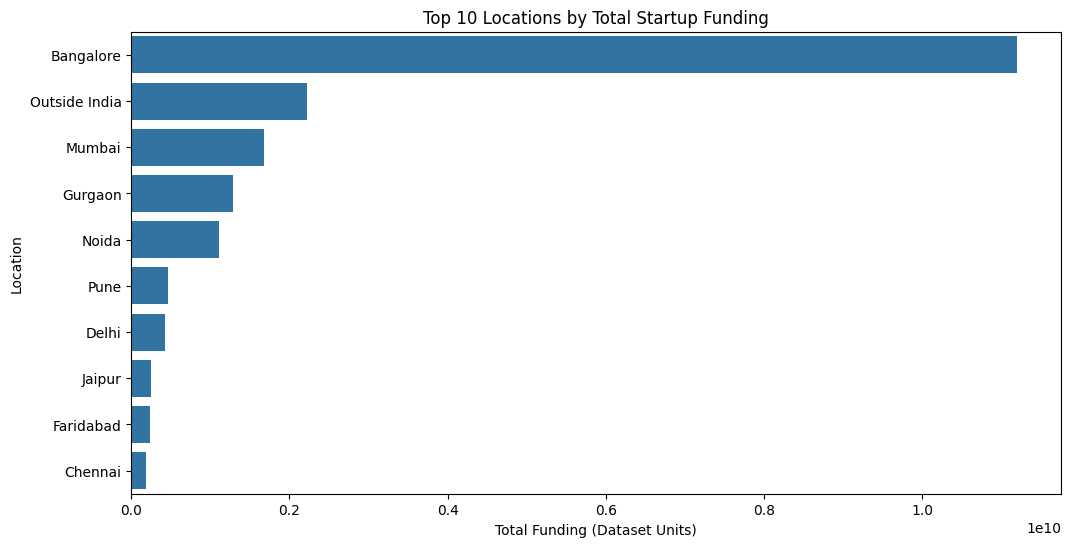

In [ ]:
top_cities = city_analysis.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_cities,
    x='Total_Funding',
    y='Location'
)

plt.title('Top 10 Locations by Total Startup Funding')
plt.xlabel('Total Funding (Dataset Units)')
plt.ylabel('Location')

plt.show()

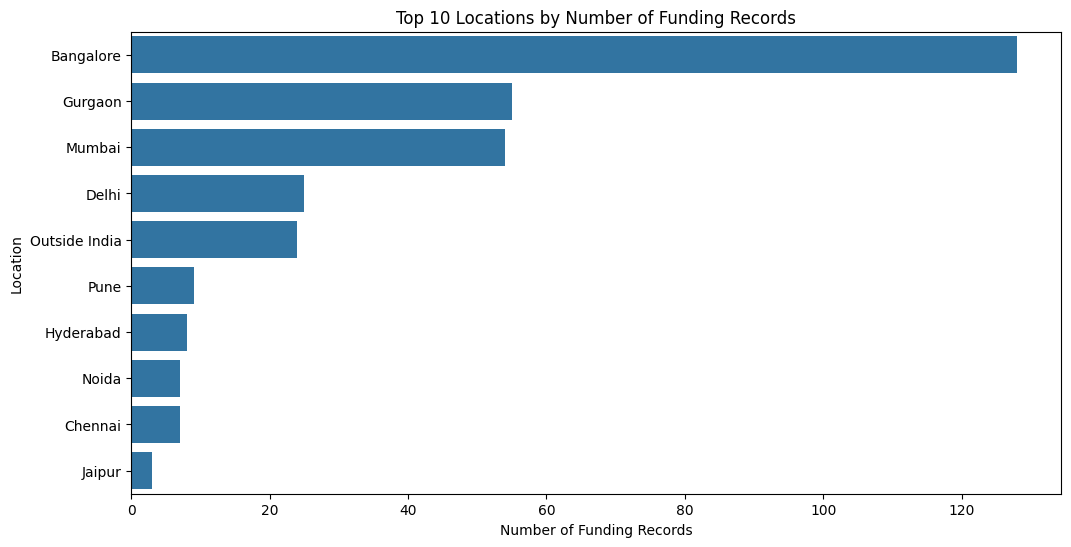

In [ ]:
city_frequency = df_clean['Location'].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=city_frequency.values,
    y=city_frequency.index
)

plt.title('Top 10 Locations by Number of Funding Records')
plt.xlabel('Number of Funding Records')
plt.ylabel('Location')

plt.show()


In [ ]:
city_analysis = df_clean.groupby('Location').agg(
    Total_Funding=('Amount', 'sum'),
    Average_Funding=('Amount', 'mean'),
    Median_Funding=('Amount', 'median'),
    Funding_Records=('Startup', 'count')
).reset_index()

city_analysis = city_analysis.sort_values(
    by='Total_Funding',
    ascending=False
)

city_analysis

,Location,Total_Funding,Average_Funding,Median_Funding,Funding_Records
2,Bangalore,1.119611e+10,8.746963e+07,8000000.0,128
15,Outside India,2.225219e+09,9.271746e+07,44540000.0,24
12,Mumbai,1.673975e+09,3.099953e+07,6125000.0,54
7,Gurgaon,1.279981e+09,2.327239e+07,10000000.0,55
14,Noida,1.113358e+09,1.590511e+08,15000000.0,7
17,Pune,4.581742e+08,5.090824e+07,4500000.0,9
5,Delhi,4.217823e+08,1.687129e+07,3591375.0,25
11,Jaipur,2.511750e+08,8.372500e+07,1000000.0,3
6,Faridabad,2.310000e+08,2.310000e+08,231000000.0,1
4,Chennai,1.862990e+08,2.661414e+07,9000000.0,7


In [ ]:
city_only = city_analysis[
    ~city_analysis['Location'].isin(['Outside India', 'Haryana'])
].copy()

city_only = city_only.sort_values(
    by='Total_Funding',
    ascending=False
)

city_only

,Location,Total_Funding,Average_Funding,Median_Funding,Funding_Records
2,Bangalore,1.119611e+10,8.746963e+07,8000000.0,128
12,Mumbai,1.673975e+09,3.099953e+07,6125000.0,54
7,Gurgaon,1.279981e+09,2.327239e+07,10000000.0,55
14,Noida,1.113358e+09,1.590511e+08,15000000.0,7
17,Pune,4.581742e+08,5.090824e+07,4500000.0,9
5,Delhi,4.217823e+08,1.687129e+07,3591375.0,25
11,Jaipur,2.511750e+08,8.372500e+07,1000000.0,3
6,Faridabad,2.310000e+08,2.310000e+08,231000000.0,1
4,Chennai,1.862990e+08,2.661414e+07,9000000.0,7
9,Hyderabad,1.075000e+08,1.343750e+07,6000000.0,8


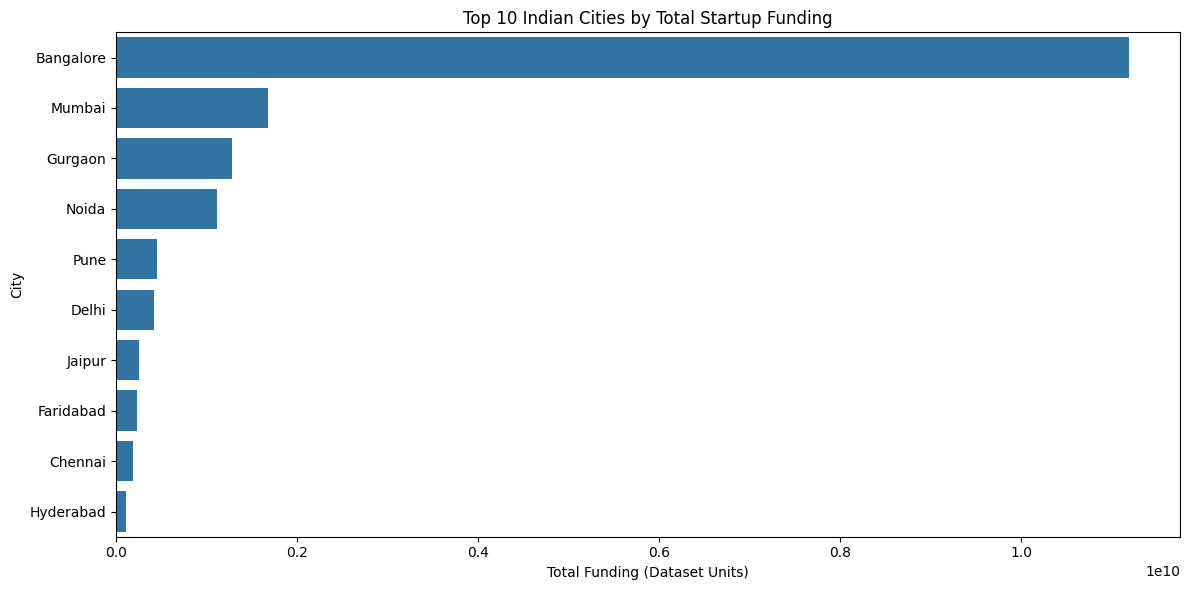

In [ ]:
top_cities = city_only.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_cities,
    x='Total_Funding',
    y='Location'
)

plt.title('Top 10 Indian Cities by Total Startup Funding')
plt.xlabel('Total Funding (Dataset Units)')
plt.ylabel('City')
plt.tight_layout()
plt.show()

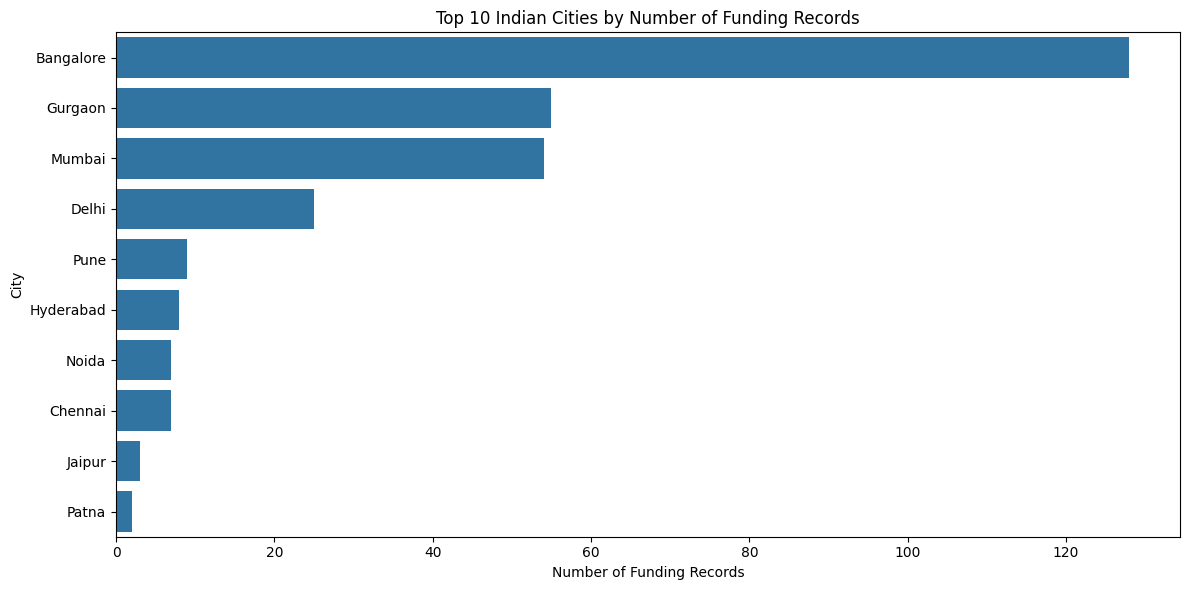

In [ ]:
city_frequency = city_only.sort_values(
    by='Funding_Records',
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=city_frequency,
    x='Funding_Records',
    y='Location'
)

plt.title('Top 10 Indian Cities by Number of Funding Records')
plt.xlabel('Number of Funding Records')
plt.ylabel('City')
plt.tight_layout()
plt.show()

In [ ]:
df_clean['Year'] = df_clean['Date'].dt.year

yearly_analysis = df_clean.groupby('Year').agg(
    Total_Funding=('Amount', 'sum'),
    Average_Funding=('Amount', 'mean'),
    Funding_Records=('Startup', 'count')
).reset_index()

yearly_analysis

,Year,Total_Funding,Average_Funding,Funding_Records
0,2018.0,2.619995e+09,2.757889e+07,95
1,2019.0,9.545919e+09,9.267882e+07,103
2,2020.0,4.045309e+09,3.927484e+07,103
3,2021.0,3.032093e+09,1.045549e+08,29


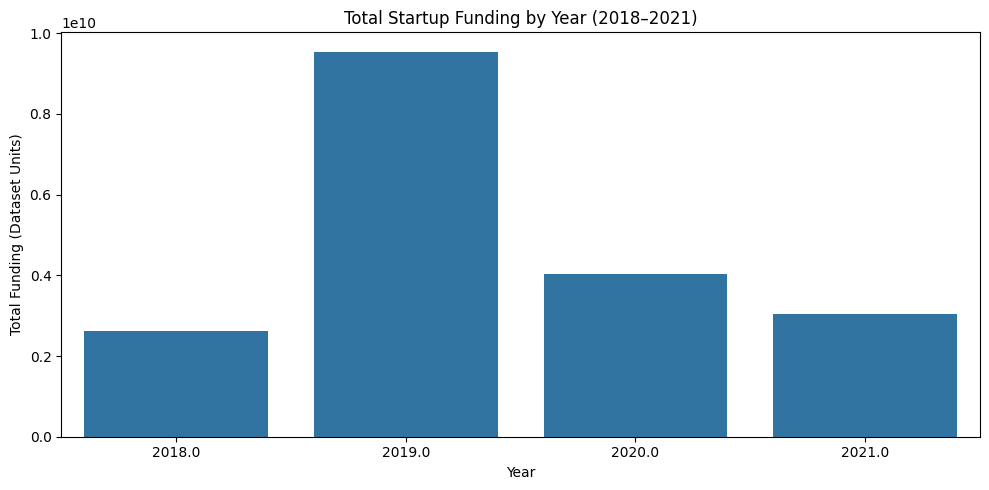

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_analysis,
    x='Year',
    y='Total_Funding'
)

plt.title('Total Startup Funding by Year (2018–2021)')
plt.xlabel('Year')
plt.ylabel('Total Funding (Dataset Units)')
plt.tight_layout()
plt.show()

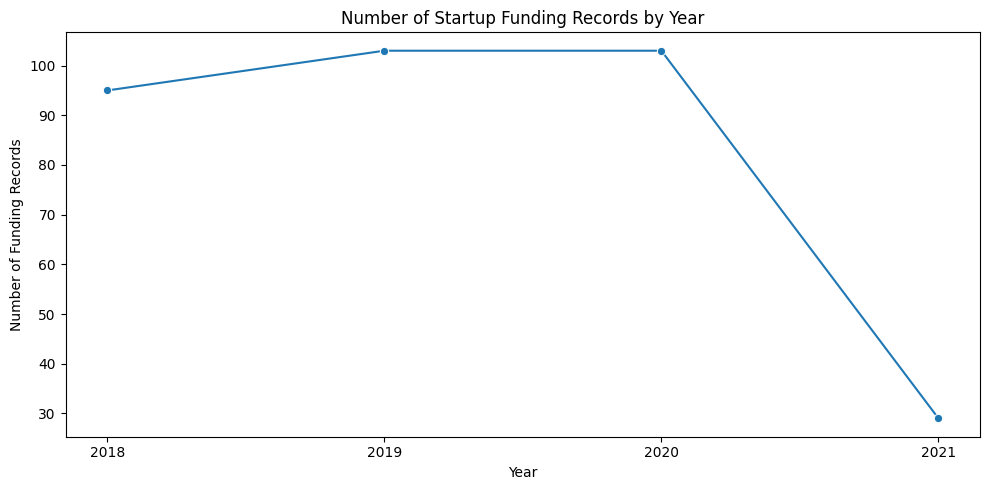

In [ ]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_analysis,
    x='Year',
    y='Funding_Records',
    marker='o'
)

plt.title('Number of Startup Funding Records by Year')
plt.xlabel('Year')
plt.ylabel('Number of Funding Records')
plt.xticks(yearly_analysis['Year'])
plt.tight_layout()
plt.show()

In [ ]:
startup_analysis = df_clean.groupby('Startup').agg(
    Total_Funding=('Amount', 'sum'),
    Average_Funding=('Amount', 'mean'),
    Funding_Records=('Amount', 'count')
).reset_index()

startup_analysis = startup_analysis.sort_values(
    by='Total_Funding',
    ascending=False
)

startup_analysis.head(10)

,Startup,Total_Funding,Average_Funding,Funding_Records
211,Rapido Bike Taxi,3.900000e+09,3.900000e+09,1
23,BYJU'S,1.770000e+09,3.540000e+08,5
102,Flipkart,1.200000e+09,1.200000e+09,1
197,Paytm,1.000000e+09,1.000000e+09,1
251,Udaan,8.100000e+08,4.050000e+08,2
250,True North,6.000000e+08,6.000000e+08,1
160,Meesho,4.750000e+08,1.583333e+08,3
107,GOQii,4.500000e+08,4.500000e+08,1
273,Zomato,4.000000e+08,2.000000e+08,2
239,Swiggy,3.860000e+08,1.930000e+08,2


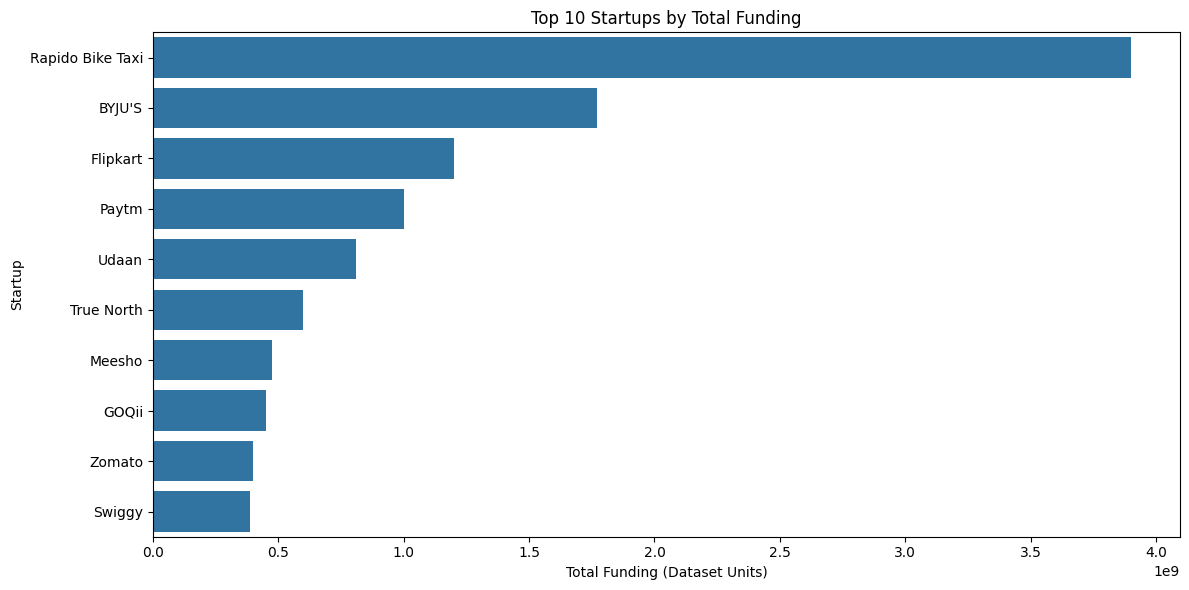

In [ ]:
top_startups = startup_analysis.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_startups,
    x='Total_Funding',
    y='Startup'
)

plt.title('Top 10 Startups by Total Funding')
plt.xlabel('Total Funding (Dataset Units)')
plt.ylabel('Startup')
plt.tight_layout()
plt.show()

In [ ]:
investor_analysis = df_clean.groupby('Investor').agg(
    Total_Funding=('Amount', 'sum'),
    Average_Funding=('Amount', 'mean'),
    Funding_Records=('Startup', 'count')
).reset_index()

investor_analysis = investor_analysis.sort_values(
    by='Total_Funding',
    ascending=False
)

investor_analysis.head(10)

,Investor,Total_Funding,Average_Funding,Funding_Records
291,Westbridge Capital,3.900000e+09,3.900000e+09,1
288,Walmart Inc,1.200000e+09,1.200000e+09,1
286,Vijay Shekhar Sharma,1.000000e+09,1.000000e+09,1
111,Innoven Capital,7.100000e+08,3.550000e+08,2
215,Secret,6.121148e+08,7.651435e+07,8
20,"Altimeter Capital, DST Global",5.850000e+08,5.850000e+08,1
138,"MC Global Edtech, B Capital, Baron, others",5.430000e+08,2.715000e+08,2
238,SoftBank Vision Fund,5.310000e+08,2.655000e+08,2
233,"Silver Lake, Tiger Global, General Atlantic an...",5.000000e+08,5.000000e+08,1
41,Bennett Coleman and Company Ltd (BCCL),4.500000e+08,4.500000e+08,1


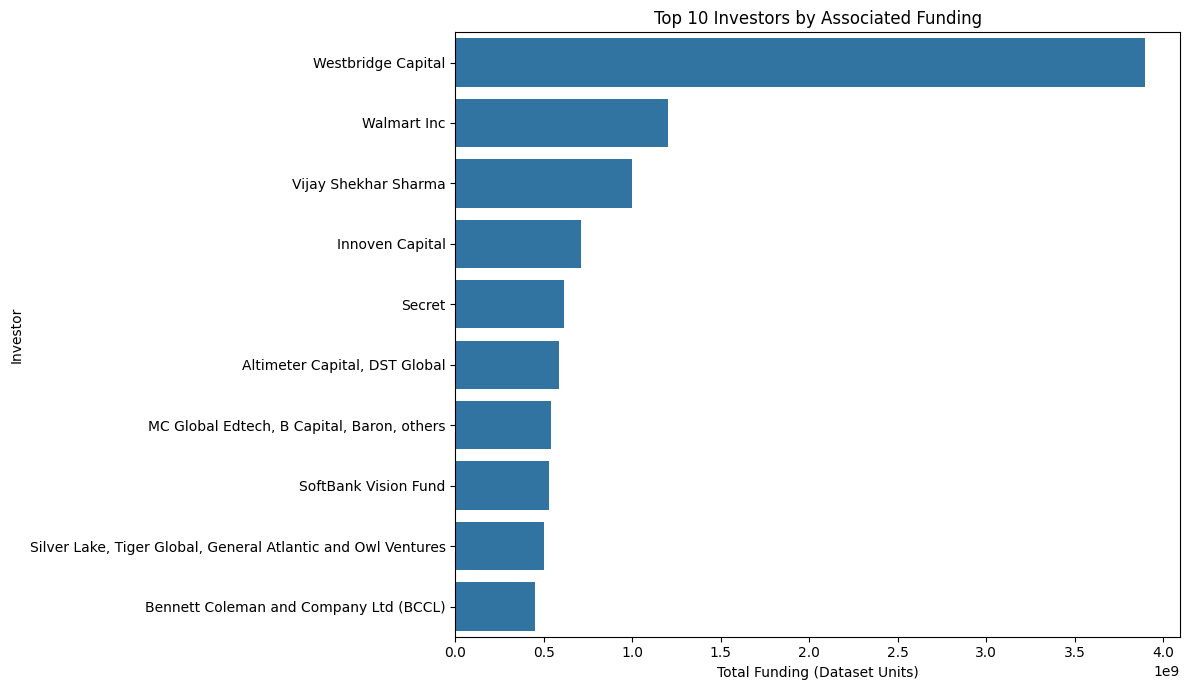

In [ ]:
top_investors = investor_analysis.head(10)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_investors,
    x='Total_Funding',
    y='Investor'
)

plt.title('Top 10 Investors by Associated Funding')
plt.xlabel('Total Funding (Dataset Units)')
plt.ylabel('Investor')
plt.tight_layout()
plt.show()

In [ ]:
funding_type_analysis = df_clean.groupby('Type').agg(
    Total_Funding=('Amount', 'sum'),
    Average_Funding=('Amount', 'mean'),
    Median_Funding=('Amount', 'median'),
    Funding_Records=('Startup', 'count')
).reset_index()

funding_type_analysis = funding_type_analysis.sort_values(
    by='Total_Funding',
    ascending=False
)

funding_type_analysis

,Type,Total_Funding,Average_Funding,Median_Funding,Funding_Records
14,Unknown,5.343921e+09,6.213861e+07,14475000.0,86
6,Series B,4.992396e+09,1.560124e+08,15304750.0,32
8,Series D,2.069360e+09,1.089137e+08,83000000.0,19
7,Series C,1.335325e+09,5.341302e+07,25000000.0,25
2,Equity and Debt,1.221160e+09,4.070533e+08,20160000.0,3
10,Series F,1.100800e+09,1.376000e+08,34500000.0,8
4,Seed,9.692237e+08,1.114050e+07,1100000.0,87
9,Series E,6.370000e+08,1.274000e+08,30000000.0,5
1,Debt,4.236755e+08,2.492209e+07,5900000.0,17
5,Series A,4.037038e+08,9.388461e+06,6000000.0,43


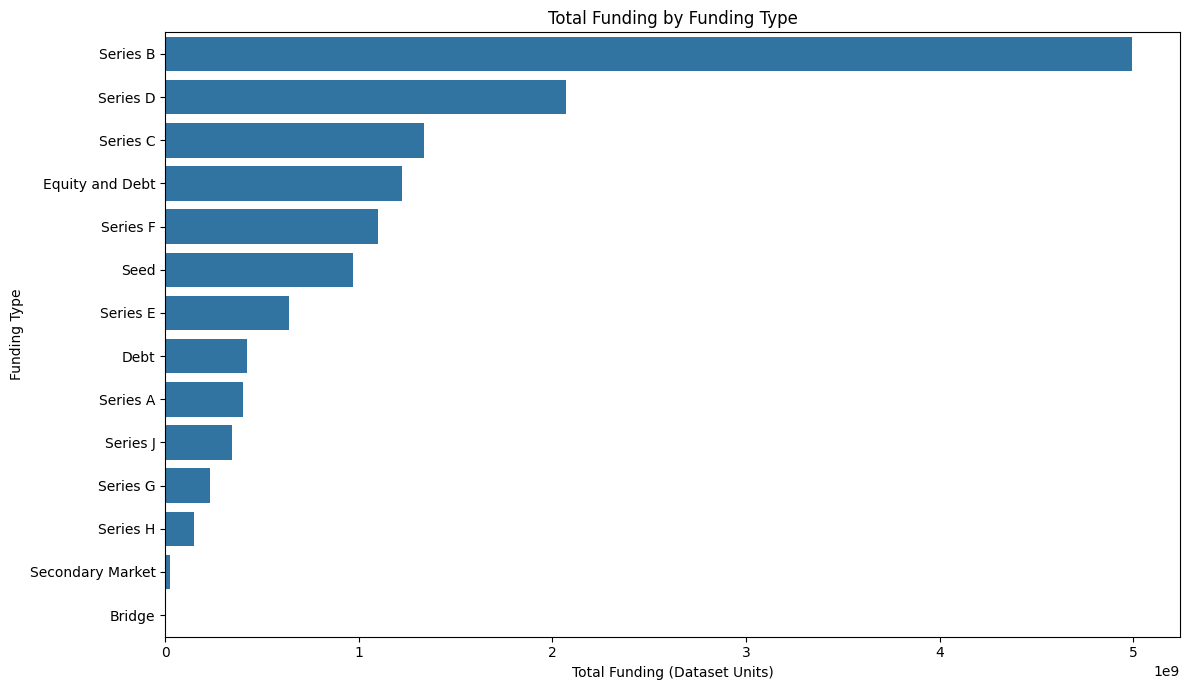

In [ ]:
known_funding_types = funding_type_analysis[
    funding_type_analysis['Type'] != 'Unknown'
].sort_values(
    by='Total_Funding',
    ascending=False
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=known_funding_types,
    x='Total_Funding',
    y='Type'
)

plt.title('Total Funding by Funding Type')
plt.xlabel('Total Funding (Dataset Units)')
plt.ylabel('Funding Type')
plt.tight_layout()
plt.show()

In [ ]:
quality_check = pd.DataFrame({
    'Column': df_clean.columns,
    'Data_Type': df_clean.dtypes.values,
    'Missing_Values': df_clean.isnull().sum().values,
    'Unique_Values': df_clean.nunique().values
})

quality_check

,Column,Data_Type,Missing_Values,Unique_Values
0,Date,datetime64[ns],1,217
1,Startup,object,0,287
2,Industry,object,0,19
3,Location,object,0,19
4,Investor,object,0,300
5,Type,object,0,15
6,Amount,float64,0,173
7,Year,float64,1,4


In [ ]:
df_clean[df_clean['Date'].isna()]

,Date,Startup,Industry,Location,Investor,Type,Amount,Year
301,NaT,Loan Tap,Software,Mumbai,"Shunwei Capital, Tuscan Ventures, Ashish Goenk...",Unknown,6250000.0,NaN


In [ ]:
pd.to_datetime(..., format='%d-%m-%Y', errors='coerce')

NaT

In [ ]:
df_clean['Year'] = df_clean['Year'].astype('Int64')

df_clean[['Date', 'Year']].dtypes

,0
Date,datetime64[ns]
Year,Int64


In [ ]:
print("Total records:", len(df_clean))

print("Missing dates:", df_clean['Date'].isna().sum())

print("Missing amounts:", df_clean['Amount'].isna().sum())

print("Duplicate records:", df_clean.duplicated().sum())

print("Zero or negative funding amounts:",
      (df_clean['Amount'] <= 0).sum())

Total records: 331
Missing dates: 1
Missing amounts: 0
Duplicate records: 0
Zero or negative funding amounts: 0


# Conclusion – Indian Startup Funding Analysis

This project analysed Indian startup funding data using Python, Pandas, Matplotlib and Seaborn.

After data cleaning and removal of duplicate records, the final dataset contained 331 records. The analysis examined funding patterns across industries, locations, years, startups, investors and funding types.

The key findings indicate that:

- Logistics recorded the highest industry-wise total funding.
- Bangalore emerged as the leading location by total funding.
- 2019 recorded the highest annual funding.
- Rapido Bike Taxi received the highest recorded startup funding.
- Westbridge Capital was associated with the largest investor-wise funding record.
- Series B recorded the highest total funding among identified funding types.

The project demonstrates how exploratory data analysis can identify funding patterns, highlight unusual transactions and support data-driven business decisions.

**Limitations:** The dataset contains one missing date, an Unknown funding-type category and potentially incomplete coverage. Its currency also requires verification. Therefore, findings should be interpreted within the scope of this dataset rather than as a complete representation of the Indian startup ecosystem.